# 02 — Initial fraud baselines

**Question:** does a simple learned model improve ranking and simulated profit over approve-all and a fixed amount rule?

Randomly allocate exact-pattern groups into **60% training, 15% selection, 10% calibration, and 15% evaluation**, stratified by group label with seed **42**. Whole groups stay together, so payment counts are approximate. `Time` remains a predictor and does not determine split membership. Calibration and evaluation are not scored here. Earlier EDA/experiments used this source population; these are development results, not a pristine final test. Costs are explicitly illustrative ([scenario](../docs/cost-scenario.md)).

**Economics:** approved legitimate = +25% of Amount; approved fraud = −100%; canceled = 0 for either label. No cancellation fee, challenge effectiveness, or abandonment assumptions are included.

## 1. Reproducible experiment

The shared script verifies source/config/split checksums, fits preprocessing on training data only, fits the classifiers, and records three **local MLflow runs**. It saves selection predictions and fitted pipeline bundles. Running this cell creates new experiment runs; it does not promote or deploy a model.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import hashlib

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.calibration import calibration_curve

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
assert (root / "config/evaluation.json").exists(), "Run from the project root or notebooks directory"
run_environment = os.environ.copy()
run_environment.update(OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1", MLFLOW_ENABLE_ASYNC_LOGGING="false")
completed = subprocess.run([sys.executable, str(root / "scripts/run_baselines.py")], cwd=root, env=run_environment, capture_output=True, text=True)
if completed.returncode:
    print(completed.stderr)
    completed.check_returncode()
print(completed.stdout)


               name  average_precision  brier_score  fraud_canceled_recall  cancellation_rate  simulated_profit_per_1000  profit_pct_of_maximum
        approve_all           0.001783      0.00178               0.000000           0.000000               21740.964182              98.670953
        amount_rule           0.003090          NaN               0.026316           0.009547               17299.275955              78.512435
logistic_regression           0.741775      0.00081               0.657895           0.001478               21811.863741              98.992729
Selection only; calibration and evaluation splits were not scored.
Saved fitted pipelines, selection predictions, report, and three local MLflow runs.



## 2. Comparators and selection metrics

- **Approve-all:** never cancel; the training fraud prevalence supplies a constant ranking/probability reference.
- **Amount rule:** cancel payments at or above the **training** Amount p99; rank by raw amount. Amount is not a probability, so Brier score is omitted.
- **Logistic regression:** standardized V1–V28, standardized `log(1 + Amount)`, and standardized elapsed `Time`. Time is available at prediction time.

The logistic model uses fixed `C=1`, no class weighting/resampling, and no post-hoc calibration. Its policy cancels a positive-amount transaction when predicted fraud probability exceeds 0.20. Expected approval profit is Amount × [0.25 × (1 − p) − p]; cancellation earns zero. At p=0.20 both actions break even, and ties favor approval. These scores may be miscalibrated, so economic results remain provisional. There is no review queue in this comparison.

In [2]:
report = json.loads((root / "reports/baseline-results.json").read_text())
metadata = report["metadata"]
assert metadata["evaluated_split"] == "selection"
assert not metadata["evaluation_split_scored"] and not metadata["calibration_split_used"]
results = pd.DataFrame(report["results"]).set_index("name")
columns = ["average_precision", "roc_auc", "brier_score", "fraud_canceled_recall", "legitimate_cancellation_rate", "cancellation_rate", "simulated_profit_per_1000", "profit_pct_of_maximum"]
display(results[columns].round(5))
print(f"Population: {metadata['selection_rows']:,} selection transactions, {metadata['selection_frauds']} frauds")
print(f"Training Amount p99 rule cutoff: {metadata['amount_rule_threshold_from_train_p99']:,.2f}")
print("Rate and ranking columns are fractions; profit relative to the perfect-label oracle is a percentage. Costs use source Amount units.")


,average_precision,roc_auc,brier_score,fraud_canceled_recall,legitimate_cancellation_rate,cancellation_rate,simulated_profit_per_1000,profit_pct_of_maximum
name,,,,,,,,
approve_all,0.00178,0.50000,0.00178,0.00000,0.00000,0.00000,21740.96418,98.67095
amount_rule,0.00309,0.49205,NaN,0.02632,0.00952,0.00955,17299.27595,78.51244
logistic_regression,0.74178,0.96429,0.00081,0.65789,0.00031,0.00148,21811.86374,98.99273


Population: 42,632 selection transactions, 76 frauds
Training Amount p99 rule cutoff: 1,006.91
Rate and ranking columns are fractions; profit relative to the perfect-label oracle is a percentage. Costs use source Amount units.


## 3. Ranking and decision value

Average precision summarizes the precision–recall curve; the constant-score reference equals selection fraud prevalence. A stronger ranking need not yield a more profitable policy: amounts, error costs, score calibration, and cancellation decisions also matter. Cancellation recall is the fraction of known frauds canceled, not the fraction proven prevented in production.

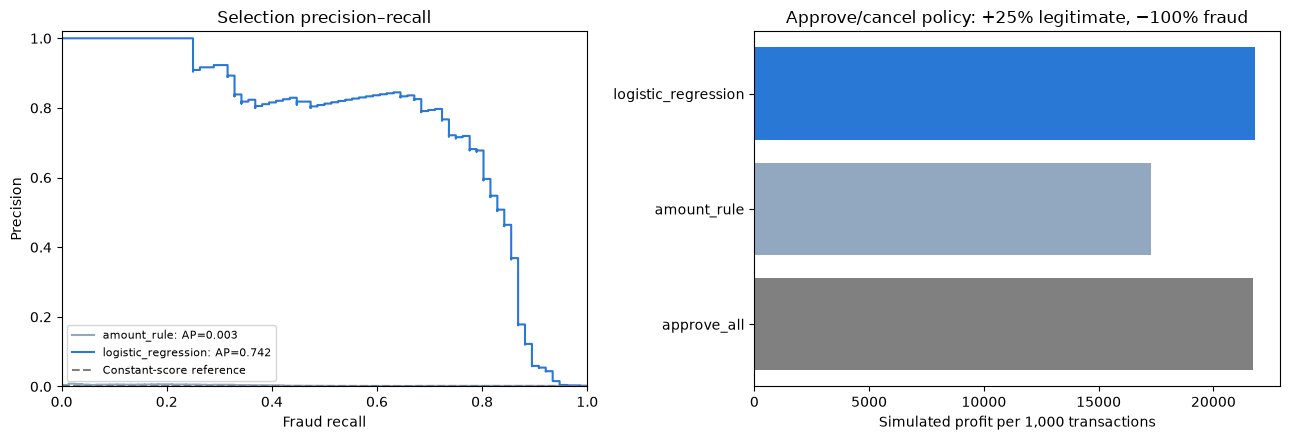

In [3]:
prediction_path = root / report["selection_predictions"]["path"]
assert hashlib.sha256(prediction_path.read_bytes()).hexdigest() == report["selection_predictions"]["sha256"]
predictions = pd.read_csv(prediction_path)
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_colors = {"amount_rule": "#91a8c0", "logistic_regression": "#2a78d6"}
for name in ["amount_rule", "logistic_regression"]:
    rows = predictions.loc[predictions["model"].eq(name)]
    precision, recall, _ = precision_recall_curve(rows["Class"], rows["score"])
    axes[0].step(recall, precision, where="post", color=plot_colors[name], label=f"{name}: AP={average_precision_score(rows['Class'], rows['score']):.3f}")
axes[0].axhline(metadata["selection_frauds"] / metadata["selection_rows"], color="gray", linestyle="--", label="Constant-score reference")
axes[0].set(xlabel="Fraud recall", ylabel="Precision", title="Selection precision–recall", xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
axes[1].barh(results.index, results["simulated_profit_per_1000"], color=["gray", "#91a8c0", "#2a78d6"])
axes[1].set(xlabel="Simulated profit per 1,000 transactions", title="Approve/cancel policy: +25% legitimate, −100% fraud")
figure.tight_layout()
figure_directory = root / "reports/figures"
figure_directory.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_directory / "baseline-selection-ranking-and-cost.png", dpi=140, bbox_inches="tight")
plt.show()


## 4. Calibration and controlled-FPR diagnostic

Brier score and reliability points diagnose probability quality. With few frauds, quantile-bin reliability is descriptive, not proof of calibration.

The threshold below targets at most 0.1% false positives **on selection itself** and reports recall there. It is a development diagnostic, not an independently validated operating threshold. It is separate from the cost-based cancel policy above.

,selection_fpr_diagnostic_recall,selection_fpr_diagnostic_realized_fpr,selection_fpr_diagnostic_threshold,selection_fpr_diagnostic_predict_none
name,,,,
approve_all,0.000000,0.000000,NaN,True
amount_rule,0.000000,0.000000,NaN,True
logistic_regression,0.815789,0.000987,0.02147,False


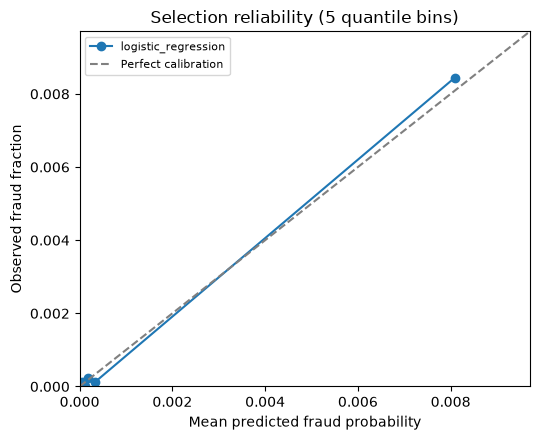

In [4]:
display(results[["selection_fpr_diagnostic_recall", "selection_fpr_diagnostic_realized_fpr", "selection_fpr_diagnostic_threshold", "selection_fpr_diagnostic_predict_none"]].round(6))
calibration_figure, calibration_axis = plt.subplots(figsize=(5.5, 4.5))
calibration_limit = 0.0
for name in ["logistic_regression"]:
    rows = predictions.loc[predictions["model"].eq(name)]
    observed, predicted = calibration_curve(rows["Class"], rows["score"], n_bins=5, strategy="quantile")
    calibration_limit = max(calibration_limit, float(max(predicted)), float(max(observed)))
    calibration_axis.plot(predicted, observed, marker="o", label=name)
calibration_axis.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
calibration_axis.set(xlabel="Mean predicted fraud probability", ylabel="Observed fraud fraction", title="Selection reliability (5 quantile bins)")
calibration_axis.set_xlim(0, calibration_limit * 1.15)
calibration_axis.set_ylim(0, calibration_limit * 1.15)
calibration_axis.legend(fontsize=8)
calibration_figure.tight_layout()
calibration_figure.savefig(figure_directory / "baseline-selection-calibration.png", dpi=140, bbox_inches="tight")
plt.show()


## 5. Expensive selection errors and saved-pipeline consistency

Inspect the largest opportunity losses versus perfect decisions rather than only counting errors. These examples use selection labels, which are available for development. The original published record can be located using `source_row_id` and the persisted assignments.

In [5]:
logistic_names = ["logistic_regression"]
for name in logistic_names:
    rows = predictions.loc[predictions["model"].eq(name)]
    print(name, "— expensive approved frauds")
    display(rows.loc[rows["Class"].eq(1) & ~rows["canceled"], ["source_row_id", "Amount", "score", "simulated_profit", "simulated_cost"]].nlargest(5, "simulated_cost"))
    print(name, "— expensive canceled legitimate payments")
    display(rows.loc[rows["Class"].eq(0) & rows["canceled"], ["source_row_id", "Amount", "score", "simulated_profit", "simulated_cost"]].nlargest(5, "simulated_cost"))
    bundle = joblib.load(root / "models/baselines" / f"{name}.joblib")
    assert "Class" not in bundle["input_columns"]
    assert bundle["posthoc_calibrated"] is False
    print("Saved bundle:", bundle["policy"], "| inputs:", len(bundle["input_columns"]))


logistic_regression — expensive approved frauds


,source_row_id,Amount,score,simulated_profit,simulated_cost
107985,151196,571.48,0.002045,-571.48,571.48
107156,145800,451.27,0.004475,-451.27,451.27
94634,61787,360.00,0.086532,-360.00,360.00
114079,192687,276.17,0.001661,-276.17,276.17
97370,79883,270.00,0.195760,-270.00,270.00


logistic_regression — expensive canceled legitimate payments


,source_row_id,Amount,score,simulated_profit,simulated_cost
126392,274771,25691.16,0.915968,0.0,6422.7900
95176,65423,500.00,0.388081,0.0,125.0000
86907,10681,89.99,0.999994,0.0,22.4975
86942,10906,89.99,0.999987,0.0,22.4975
87268,12938,89.99,0.999808,0.0,22.4975


Saved bundle: cancel_when_expected_profit_negative | inputs: 30


## 6. Decision and next experiment

Use these selection results to identify a development candidate, not to declare a production winner. Compare with a boosted tree next, assess whether any gain exceeds uncertainty, then fit calibration and develop policy using the reserved calibration split. The final evaluation remains deferred.

Inspect local experiments from the project root with `poetry run mlflow server --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5050 --workers 1`, then open `http://127.0.0.1:5050`. Fitted models, tracking data, and row-level predictions are local artifacts; committed reports and the lockfile provide the reproducible record.

In [6]:
print("Highest assumed selection profit:", results["simulated_profit_per_1000"].idxmax())
print("Highest selection average precision:", results["average_precision"].idxmax())
print("These are selection estimates under the user-specified profit scenario; no model is promoted.")


Highest assumed selection profit: logistic_regression
Highest selection average precision: logistic_regression
These are selection estimates under the user-specified profit scenario; no model is promoted.
